# Declarus · Статистическая проверка H1 и H2 на 50 документах

- **Гипотеза 1:** Если добавить три размеченных few-shot примера в запрос к Qwen без изменения её весов, то на независимой тестовой выборке прирост field-level micro-F1 относительно zero-shot составит более 0 процентных пунктов, причём нижняя граница 95%-го доверительного интервала прироста будет выше 0 п.п.
- **Гипотеза 2:** Если дополнить OCR-данные изображением упаковочного листа, то на независимой тестовой выборке прирост field-level micro-F1 относительно обработки только OCR-данных составит более 0 процентных пунктов, причём нижняя граница 95%-го доверительного интервала прироста будет выше 0 п.п.

## Условия и границы интерпретации

Один и тот же набор: **50 синтетических документов, 6 шаблонов, 362 эталонные товарные строки**. Три шаблона родственны демонстрациям; независимости по семействам шаблонов нет. Проверяется эффект на данном наборе, перенос на новые формы не установлен. Если промпт настраивался по этому тесту, нужна новая отложенная выборка.

- H1: **OCR + изображение + 3 примера** против **OCR + изображение без примеров**.
- H2: **OCR + изображение без примеров** против **только OCR без примеров**.

- Field-level micro-F1 = `2TP/(2TP+FP+FN)` по суммарным счётчикам. 

In [1]:
from pathlib import Path
import os, json, hashlib, sys
import pandas as pd
from IPython.display import display, Markdown
ROOT=next((p for p in [Path.cwd(), *Path.cwd().parents]
           if (p/'research/data/manifest.json').exists()), None)
if ROOT is None: raise FileNotFoundError('Запускайте ноутбук внутри проекта с сохранёнными отчётами.')
WORK=ROOT/'research/reports'
os.environ.setdefault('MPLCONFIGDIR',str(WORK/'.mpl-cache'))
import matplotlib.pyplot as plt
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.dpi':120,
                     'axes.spines.top':False,'axes.spines.right':False})
paths={'H1':ROOT/'research/reports/fewshot_comparison.json',
       'H2':ROOT/'research/reports/image_comparison.json'}
reports={k:json.loads(p.read_text()) for k,p in paths.items()}
assert reports['H2']['all_attempts_finished']
assert all(s['documents']==50 for report in reports.values() for s in report['summary'].values())
print('Локальный анализ сохранённых ответов. API-вызовов нет. Python:',sys.version.split()[0])


Matplotlib is building the font cache; this may take a moment.


Локальный анализ сохранённых ответов. API-вызовов нет. Python: 3.13.5


## 1. Источники и сопоставимость

In [2]:
display(pd.DataFrame([{'Гипотеза':k,'Источник':str(p.relative_to(ROOT)),
    'SHA-256':hashlib.sha256(p.read_bytes()).hexdigest()} for k,p in paths.items()]))
settings=reports['H2']['config']
display(pd.DataFrame([{'Модель':settings['model'],'temperature':settings['temperature'],
    'reasoning':str(settings['reasoning']),'Лимит выхода':settings['max_output_tokens'],
    'Промпт SHA-256':settings['prompt_sha256']}]))
assert all(reports['H1']['config'][k]==settings[k] for k in
           ['model','temperature','reasoning','max_output_tokens','prompt_sha256','manifest_sha256','evaluator_sha256'])
image_rows={r['document_id']:r for r in reports['H2']['runs']['ocr_image']}
zero_rows={r['document_id']:r for r in reports['H1']['runs']['zero_shot']}
assert set(image_rows)==set(zero_rows) and len(image_rows)==50
assert all(image_rows[d]['metrics']['counts']==zero_rows[d]['metrics']['counts'] for d in image_rows)
print('Общий режим OCR + изображение в H1 и H2 совпадает; настройки и оценщик сверены.')


,Гипотеза,Источник,SHA-256
0,H1,research/reports/fewshot_comparison.json,7515441da8ff17544e99cc2cd6174ece598e487796ecc8...
1,H2,research/reports/image_comparison.json,944c03fc57c4147198b8782d34d1298be74ffb2519eaeb...


,Модель,temperature,reasoning,Лимит выхода,Промпт SHA-256
0,qwen3.6-35b-a3b,0.1,{'effort': 'none'},40000,4bc4bb96df6b0aba44dcea0d08d7150bd3e5ff22e05abd...


Общий режим OCR + изображение в H1 и H2 совпадает; настройки и оценщик сверены.


## 2. Метод: парный bootstrap по документам

20 000 повторов. В каждом повторе выбираются 50 документов с возвращением; одни и те же идентификаторы используются в обоих режимах. TP/FP/FN суммируются с учётом повторений, затем micro-F1 пересчитывается заново. Интервал — процентили 2,5% и 97,5% прироста в п.п.

Пересэмплирование полей и усреднение F1 документов не используются. Интервал описывает неопределённость состава документов при фиксированных ответах. Это два индивидуальных 95% интервала без поправки на совместную проверку. Стратификация по шаблонам — проверка чувствительности при фиксированном числе документов каждого шаблона, не проверка новых шаблонов.

In [3]:
import random
B=20_000
SEED=20261107
KEYS=('true_positive','false_positive','false_negative')

def counts(row):
    return tuple(row['metrics']['counts'][k] for k in KEYS)


def f1(rows):
    tp, fp, fn = (sum(x[i] for x in rows) for i in range(3))
    return 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0


def percentile(values, q):
    a = sorted(values)
    pos = (len(a) - 1) * q
    lo = int(pos)
    hi = min(lo + 1, len(a) - 1)
    return a[lo] + (a[hi] - a[lo]) * (pos - lo)


def check(name, baseline, treatment, groups=None):
    assert set(baseline) == set(treatment) and baseline
    ids = sorted(baseline)
    for d in ids:
        assert all(v >= 0 for v in baseline[d] + treatment[d])
        assert baseline[d][0] + baseline[d][2] == treatment[d][0] + treatment[d][2]
    strata = [ids] if groups is None else [[d for d in ids if groups[d] == g] for g in sorted(set(groups.values()))]
    rng = random.Random(SEED)
    deltas = []
    for _ in range(B):
        selected = [rng.choice(group) for group in strata for _ in group]
        deltas.append(100 * (f1([treatment[d] for d in selected]) - f1([baseline[d] for d in selected])))
    low, high = percentile(deltas, .025), percentile(deltas, .975)
    result = {'name': name, 'documents': len(ids), 'resampling': 'paired_documents' if groups is None else 'paired_documents_within_template',
              'baseline_f1_percent': 100*f1(list(baseline.values())), 'treatment_f1_percent': 100*f1(list(treatment.values())),
              'delta_f1_pp': 100*(f1(list(treatment.values()))-f1(list(baseline.values()))),
              'ci95_pp': [low, high], 'positive_effect_supported': low > 0,
              'degenerate_distribution': min(deltas) == max(deltas),
              'document_counts': [{'id': d, 'baseline_tp_fp_fn': baseline[d], 'treatment_tp_fp_fn': treatment[d]} for d in ids]}
    return result, deltas



## 3. Проверки и расчёт двух гипотез

In [4]:
assert f1([(3,1,2)])==6/9
assert check('identity',{'a':(3,1,2)},{'a':(3,1,2)})[0]['ci95_pp']==[0,0]
assert check('positive',{'a':(0,0,2)},{'a':(2,0,0)})[0]['ci95_pp']==[100,100]
results={};draws={}
mode_pairs={'H1':('zero_shot','few_shot_3'),'H2':('ocr_only','ocr_image')}
for h,(baseline,treatment) in mode_pairs.items():
    rows=reports[h]['runs']
    a={x['document_id']:counts(x) for x in rows[baseline]}
    b={x['document_id']:counts(x) for x in rows[treatment]}
    assert set(a)==set(b) and len(a)==50
    for mode,values in [(baseline,a),(treatment,b)]:
        assert abs(f1(list(values.values()))-reports[h]['summary'][mode]['field_f1'])<1e-12
        assert tuple(sum(x[i] for x in values.values()) for i in range(3))==tuple(reports[h]['summary'][mode]['counts'][k] for k in KEYS)
    name=h+('_fewshot' if h=='H1' else '_image')
    results[h],draws[h]=check(name+'_all_50',a,b)
    valid=set.intersection(*[{x['document_id'] for x in rows[m] if x['json_valid']} for m in [baseline,treatment]])
    if valid:
        results[h+'_successful'],_=check(name+'_successful_pairs',{d:a[d] for d in valid},{d:b[d] for d in valid})
    groups={x['document_id']:x['template'] for x in rows[baseline]}
    results[h+'_stratified'],_=check(name+'_template_stratified_sensitivity',a,b,groups)
def presentation(key,x):
    return {'Расчёт':key,'n':x['documents'],'Baseline F1, %':x['baseline_f1_percent'],
            'Новый режим F1, %':x['treatment_f1_percent'],'ΔF1, п.п.':x['delta_f1_pp'],
            '95% ДИ: низ':x['ci95_pp'][0],'95% ДИ: верх':x['ci95_pp'][1],
            'Нижняя граница > 0':x['positive_effect_supported']}
display(pd.DataFrame([presentation(h,results[h]) for h in ['H1','H2']]).round(2))


,Расчёт,n,"Baseline F1, %","Новый режим F1, %","ΔF1, п.п.",95% ДИ: низ,95% ДИ: верх,Нижняя граница > 0
0,H1,50,85.58,95.17,9.60,5.73,13.63,True
1,H2,50,87.55,85.58,-1.98,-4.50,0.35,False


## 4. Распределения прироста

Гистограммы показывают bootstrap-оценки прироста. Пунктир — границы 95% ДИ; ноль означает отсутствие прироста.

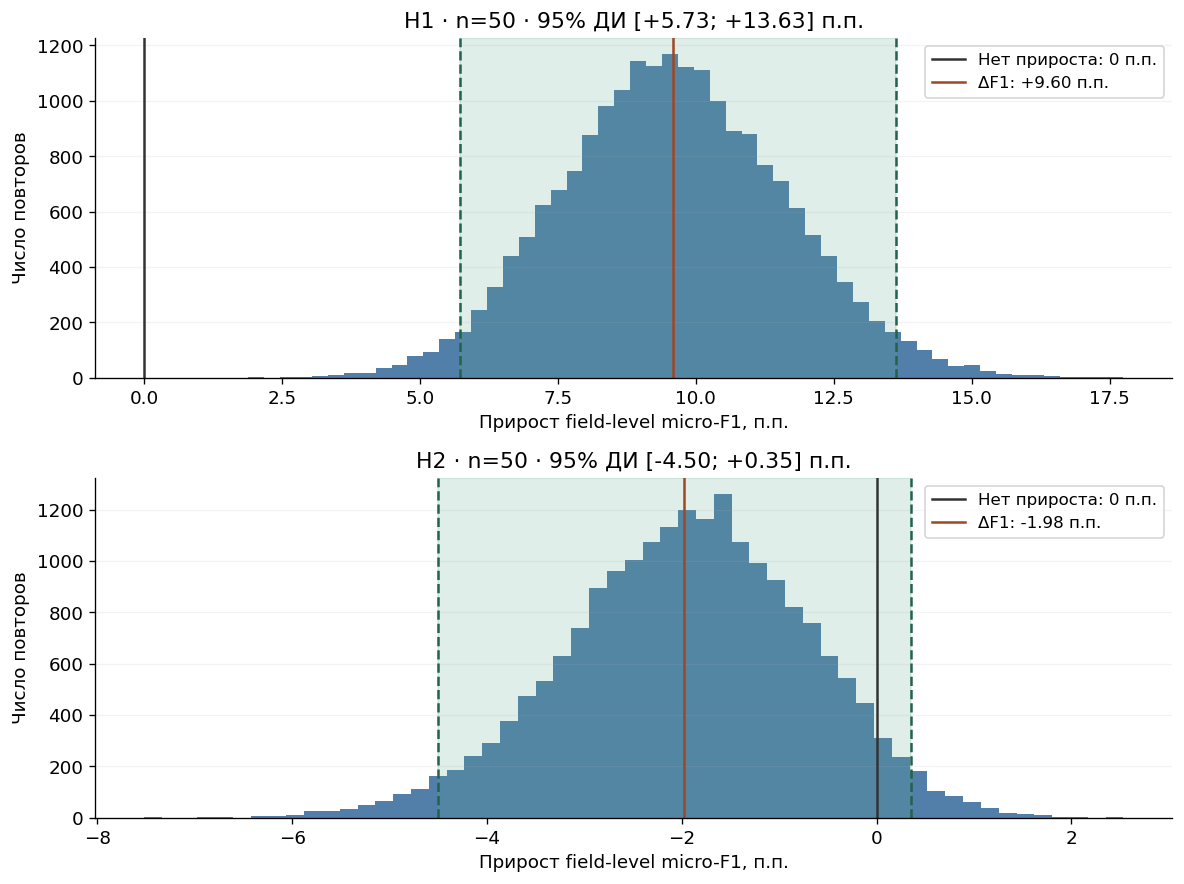

In [5]:
fig,axes=plt.subplots(2,1,figsize=(10,7.5))
for ax,h in zip(axes,['H1','H2']):
    x=results[h];lo,hi=x['ci95_pp']
    ax.hist(draws[h],bins=55,color='#34699A',alpha=.85)
    ax.axvline(0,color='#333333',label='Нет прироста: 0 п.п.')
    ax.axvspan(lo,hi,color='#52A68A',alpha=.18)
    for value in [lo,hi]:ax.axvline(value,color='#22634A',linestyle='--')
    ax.axvline(x['delta_f1_pp'],color='#A14622',label=f"ΔF1: {x['delta_f1_pp']:+.2f} п.п.")
    ax.set(title=f'{h} · n=50 · 95% ДИ [{lo:+.2f}; {hi:+.2f}] п.п.',
           xlabel='Прирост field-level micro-F1, п.п.',ylabel='Число повторов')
    ax.legend(fontsize=10);ax.grid(axis='y',alpha=.15)
fig.tight_layout();fig.savefig(WORK/'two_hypotheses_bootstrap.png',bbox_inches='tight');plt.show()


## 5. Проверки чувствительности

Основными остаются все 50 попыток. Анализ успешных пар условен на успешное завершение; стратифицированный анализ условен на данный набор шаблонов.

In [6]:
display(pd.DataFrame([presentation(k,x) for k,x in results.items()]).round(2))

,Расчёт,n,"Baseline F1, %","Новый режим F1, %","ΔF1, п.п.",95% ДИ: низ,95% ДИ: верх,Нижняя граница > 0
0,H1,50,85.58,95.17,9.60,5.73,13.63,True
1,H1_successful,49,85.99,95.13,9.14,5.25,13.03,True
2,H1_stratified,50,85.58,95.17,9.60,7.36,12.03,True
3,H2,50,87.55,85.58,-1.98,-4.50,0.35,False
4,H2_successful,49,87.43,85.99,-1.45,-3.75,0.69,False
5,H2_stratified,50,87.55,85.58,-1.98,-4.40,0.11,False


## 6. Выводы и воспроизводимость

In [7]:
reference=json.loads((WORK/'bootstrap_results.json').read_text())
ref={x['name']:x for x in reference['results']}
for key,x in results.items():
    expected=ref[x['name']]
    assert abs(x['delta_f1_pp']-expected['delta_f1_pp'])<1e-12
    assert all(abs(a-b)<1e-12 for a,b in zip(x['ci95_pp'],expected['ci95_pp']))
for p,source in zip(paths.values(),reference['sources']):
    assert hashlib.sha256(p.read_bytes()).hexdigest()==source['sha256']
for h in ['H1','H2']:
    x=results[h];lo,hi=x['ci95_pp']
    conclusion='Численный критерий выполнен на данном наборе.' if lo>0 else 'Численный критерий положительного эффекта не выполнен.'
    display(Markdown(f"**{h}:** ΔF1 **{x['delta_f1_pp']:+.2f} п.п.**, 95% ДИ **[{lo:+.2f}; {hi:+.2f}] п.п.** {conclusion}"))


**H1:** ΔF1 **+9.60 п.п.**, 95% ДИ **[+5.73; +13.63] п.п.** Численный критерий выполнен на данном наборе.

**H2:** ΔF1 **-1.98 п.п.**, 95% ДИ **[-4.50; +0.35] п.п.** Численный критерий положительного эффекта не выполнен.